# Multivariate time-varying PSD

This example estimates two power spectra and their **complex** cross-spectrum using plain Cholesky tensor splines. Both the power and the correlation change with time. There is no ANOVA decomposition.

We generate independent, zero-mean proper complex Gaussian coefficient vectors directly. This makes the observation likelihood exact and isolates the inference calculation. It is an intentionally small, informative example: **one simulation is not an uncertainty-calibration study**, and it does not validate a time-series transform or a LISA analysis.

The saved run has zero divergences, no maximum-depth hits, and maximum $\widehat R=1.0039$. The diagnostics and recovery plots below show what those checks cover.

Run the cells in order. The fit uses four NUTS chains, each with 1,000 warmup iterations and 1,000 retained draws. On a laptop, allow a few minutes including compilation. For a fresh environment, install the core revision used for this tutorial before starting the kernel:

```bash
python -m pip install "LogPSplinePSD @ git+https://github.com/nz-gravity/LogPSplinePSD.git@ef04c24f5c15c0dae8864e419f06c43e9687c50f"
```

In [1]:
import os
import time as timer
import warnings

os.environ.setdefault("XLA_FLAGS", "--xla_force_host_platform_device_count=1")
import jax
jax.config.update("jax_enable_x64", True)

import arviz_stats as azs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

from log_psplines import LogPSpline, PowerConfig, SplineBasis, WishartGridData, fit
from log_psplines.diagnostics.sampling import sampling_diagnostics
from log_psplines.logger import set_level

set_level("WARNING")
warnings.filterwarnings(
    "ignore", message="There are not enough devices to run parallel chains.*",
    category=UserWarning, module="log_psplines.inference.nuts",
)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})
SEED = 31415
rng = np.random.default_rng(SEED)
print(f"JAX: {jax.__version__}; float64: {jax.config.x64_enabled}")
print(f"Fixed simulation and sampler seed: {SEED}")
print("Four chains run sequentially on one JAX device.")

JAX: 0.9.1; float64: True
Fixed simulation and sampler seed: 31415
Four chains run sequentially on one JAX device.


## 1. Four smooth fields describe the whole matrix

Write

$$
T=\begin{pmatrix}1&0\\-\theta&1\end{pmatrix},\qquad
D=\operatorname{diag}(e^{h_1},e^{h_2}),\qquad
S=T^{-1}D\,T^{-H}.
$$

Here $h_j=\log D_{jj}$ is a **log innovation variance**. In the package, fields named `delta` represent this logarithm. They are not standard deviations. The four real spline fields are $h_1,h_2,\Re\theta,\Im\theta$; in general there are $p^2$ fields for $p$ channels.

For two channels, multiplication gives

$$
S_{11}=e^{h_1},\qquad S_{12}=e^{h_1}\overline\theta,\qquad
S_{22}=e^{h_2}+|\theta|^2e^{h_1}.
$$

Thus **$\theta$ is a regression coefficient, not the cross-spectrum**. We use the convention $S_{12}=E[x_1x_2^*]$, so the imaginary part of $S_{12}$ has the opposite sign to that of $\theta$. Positive diagonal innovations make every reconstructed matrix Hermitian positive definite.

In [2]:
# Smooth analytic truth, constructed independently of the package reconstruction.
time = np.linspace(0.0, 1.0, 8)
frequency = np.linspace(0.03, 0.47, 24)
t, f = np.meshgrid(time, frequency, indexing="ij")
u = t - 0.5
v = 2 * (f - frequency.min()) / np.ptp(frequency) - 1
h1 = 0.9 * u + 0.8 * v**2 + 0.35 * t * v
h2 = -0.3 - 0.65 * u + 0.45 * v + 0.4 * u * v
theta = (0.35 + 0.30 * u - 0.15 * v) + 1j * (0.20 - 0.16 * u + 0.10 * v + 0.10 * u * v)
d1, d2 = np.exp(h1), np.exp(h2)
truth = np.empty((*t.shape, 2, 2), dtype=complex)
truth[..., 0, 0] = d1
truth[..., 0, 1] = d1 * theta.conj()
truth[..., 1, 0] = truth[..., 0, 1].conj()
truth[..., 1, 1] = d2 + abs(theta)**2 * d1
truth_coherence = abs(truth[..., 0, 1])**2 / (truth[..., 0, 0].real * truth[..., 1, 1].real)

assert np.linalg.eigvalsh(truth).min() > 0
assert np.max(abs(truth[-1] - truth[0])) > 0.5
assert np.max(abs(truth[..., 0, 1].real)) > 0
assert np.max(abs(truth[..., 0, 1].imag)) > 0
print(f"Truth: {len(time)} times × {len(frequency)} frequencies × 2 channels")
print(f"Minimum eigenvalue: {np.linalg.eigvalsh(truth).min():.3f}")
print(f"Squared coherence range: {truth_coherence.min():.3f}–{truth_coherence.max():.3f}")

Truth: 8 times × 24 frequencies × 2 channels
Minimum eigenvalue: 0.192
Squared coherence range: 0.064–0.788


## 2. Generate observations with a known likelihood

At each $(t,f)$, generate 32 independent vectors $x_r\sim\mathcal{CN}(0,S(t,f))$, independently across cells too. If $z=(a+ib)/\sqrt2$ with independent standard normal $a,b$, then $E[zz^H]=I$ and $E[zz^T]=0$. Multiplication by a Cholesky factor of $S$ gives the required covariance.

The input contains $Y=\sum_r x_rx_r^H$ and the observation count, **not** their average. Replicates are separate Gaussian observations, not adjacent or overlapping transform tiles. We adopt one-sided PSD units for this toy covariance directly; no Fourier normalization or two-sided-to-one-sided conversion is being performed here. ENBW is one.

In [3]:
n_replicates = 32
z = (rng.normal(size=(*t.shape, 2, n_replicates))
     + 1j * rng.normal(size=(*t.shape, 2, n_replicates))) / np.sqrt(2)
coefficients = np.linalg.cholesky(truth) @ z
data = WishartGridData.from_coefficients(
    coefficients, time, frequency, units="arbitrary_unit^2/Hz",
    preprocessing={"source": "independent zero-mean proper complex Gaussian simulation"},
)
assert np.all(data.counts == n_replicates)
assert data.enbw == 1.0
print(f"Independent vectors: {int(data.counts.sum()):,}; observations per cell: {n_replicates}")
print(f"Stored factor width: {data.u_re.shape[-1]} (compression preserves Y and counts)")

Independent vectors: 6,144; observations per cell: 32
Stored factor width: 2 (compression preserves Y and counts)


## 3. Fit plain tensor splines, integrating the cross coefficients

Each real field has the form $B_tWB_f^T$. We use three time coefficients and four frequency coefficients per field. This small basis can represent the analytic fields above; the fit receives **only the observations, coordinates and model**, never the truth.

For ENBW one, the row log likelihood, up to constants, is

$$
\ell_j=-\sum_{t,f}\left[n_{tf}h_j(t,f)+e^{-h_j(t,f)}
\sum_r\left|x_{jr}(t,f)-\sum_{l<j}\theta_{jl}(t,f)x_{lr}(t,f)\right|^2\right].
$$

Holding $h_j$ and the smoothing scales fixed, the **squared modulus** is quadratic in the real and imaginary spline coefficients of $\theta$. With their Gaussian prior, these coefficients have a joint Gaussian conditional posterior. The sampler integrates that Gaussian exactly, then draws from its **correlated joint conditional distribution** for every retained sample. This preserves cross-spectrum uncertainty; it is not a plug-in conditional mean. See the [stationary multivariate example](multivariate-example.ipynb) for the completion-of-the-square algebra.

For each field, the tensor prior precision is

$$
Q=\sigma_t^{-2}(P_t\otimes I_f)+\sigma_f^{-2}(I_t\otimes P_f),
\qquad \sigma_t,\sigma_f\sim\operatorname{HalfNormal}(1.28).
$$

Here both derivative penalties use **maximum-entry normalization**, with a $10^{-6}$ ridge in the frequency penalty and no extra tensor/null-mode prior. These choices define the prior: trace-normalized penalties, a separate null-space prior, or different smoothing-scale hyperpriors generally give a different posterior even with the same Cholesky and tensor algebra.

The sampled log-variance coefficients automatically use coordinates combining their prior scale with fixed likelihood information. No user scaling constants are needed, and the physical prior is unchanged. NUTS adapts its step size and mass matrix during warmup. This matrix path currently supports NUTS; scalar VI support does not imply matrix VI support.

In [4]:
basis_time = SplineBasis.from_grid(
    time, 0, degree=2, penalty_order=2, normalization="max", ridge=0.0,
)
basis_frequency = SplineBasis.from_grid(
    frequency, 1, degree=2, penalty_order=2, normalization="max", ridge=1e-6,
)
model = LogPSpline(frequency=basis_frequency, time=basis_time)
config = PowerConfig(
    structure="tensor", method="nuts", roughness_scale=1.28,
    n_warmup=1000, n_samples=1000, num_chains=4, seed=SEED,
    target_accept_prob=0.95, max_tree_depth=10, dense_mass=True,
    spectrum_draws=50, spectrum_chunk_size=8, progress_bar=False,
)
print(f"Basis per field: {basis_time.basis.shape[1]} × {basis_frequency.basis.shape[1]}")
started = timer.perf_counter()
result = fit(data, config, model=model)
elapsed_seconds = timer.perf_counter() - started
assert result.metadata["theta_parameterization"] == "marginalized"
print(f"Fit and reconstruction: {elapsed_seconds:.1f} seconds")
print(f"NUTS dimensions per Cholesky row: {result.metadata['row_latent_dimensions']}")
print(f"Retained posterior: {result.posterior.sizes['chain']} chains × {result.posterior.sizes['draw']} draws")

Basis per field: 3 × 4


Fit and reconstruction: 26.5 seconds
NUTS dimensions per Cholesky row: [14, 18]
Retained posterior: 4 chains × 1000 draws


## 4. Inspect convergence before interpreting the curves

The two Cholesky rows are sampled as separate factors. We inspect divergences and maximum-depth hits for each row, plus rank-normalized $\widehat R$, bulk/tail effective sample sizes, and energy BFMI across chains. The checks below use $\widehat R<1.01$, ESS at least 400, BFMI at least 0.3, and no divergences or depth hits. Passing these checks supports this run's numerical reliability; it does not establish interval calibration or absence of model bias.

In [5]:
row_diagnostics = pd.DataFrame(sampling_diagnostics(result)["nuts"])
display(row_diagnostics.drop(columns=["step_size", "n_draws"]))
diagnostics = azs.summary(result.to_arviz(), kind="diagnostics", round_to="none")
bfmi_by_row = {}
for row in range(2):
    energy = np.asarray(result.sample_stats[f"energy_channel_{row}"])
    bfmi_by_row[row] = np.mean(np.diff(energy, axis=1)**2, axis=1) / np.var(energy, axis=1, ddof=1)
diagnostics_finite = (
    np.isfinite(diagnostics[["r_hat", "ess_bulk", "ess_tail"]].to_numpy()).all()
    and np.isfinite(list(bfmi_by_row.values())).all()
)
diagnostic_values = {
    "Maximum R-hat": float(diagnostics["r_hat"].max()),
    "Minimum bulk ESS": float(diagnostics["ess_bulk"].min()),
    "Minimum tail ESS": float(diagnostics["ess_tail"].min()),
    "Minimum BFMI": float(np.min(list(bfmi_by_row.values()))),
    "Divergences": int(row_diagnostics.divergences.sum()),
    "Maximum-depth hits": int(row_diagnostics.max_treedepth_hits.sum()),
}
display(pd.Series(diagnostic_values, name="Observed value").to_frame())
convergence_passed = (
    diagnostics_finite
    and diagnostic_values["Maximum R-hat"] < 1.01
    and diagnostic_values["Minimum bulk ESS"] >= 400
    and diagnostic_values["Minimum tail ESS"] >= 400
    and diagnostic_values["Minimum BFMI"] >= 0.3
    and diagnostic_values["Divergences"] == 0
    and diagnostic_values["Maximum-depth hits"] == 0
)
print("All R-hat, ESS and BFMI values finite:", diagnostics_finite)
print("Convergence checks:", "PASS" if convergence_passed else "NOT ALL PASSED — inspect before interpreting")

# Percentiles use every retained draw; spectrum_draws controls only a stored preview.
real_q = result.quantiles(kind="real").values
imag_q = result.quantiles(kind="imag").values
coherence_q = result.quantiles(kind="coherence").values[..., 0, 1]
median = real_q[1] + 1j * imag_q[1]
preview = result.spectral_density
assert np.isfinite(preview).all()
np.testing.assert_allclose(preview, preview.conj().swapaxes(-1, -2), atol=1e-12)
assert np.linalg.eigvalsh(preview).min() > 0
print(f"Stored {preview.shape[0]} × {preview.shape[1]}-draw matrix preview is finite, Hermitian and positive definite.")

,factor,divergences,rhat_max,ess_bulk_min,ess_tail_min,max_treedepth_hits
0,0,0,1.0,3836.0,1800.0,0
1,1,0,1.0,3641.0,2111.0,0


,Observed value
Maximum R-hat,1.003873
Minimum bulk ESS,3641.155638
Minimum tail ESS,1800.631092
Minimum BFMI,0.925351
Divergences,0.000000
Maximum-depth hits,0.000000


All R-hat, ESS and BFMI values finite: True
Convergence checks: PASS
Stored 4 × 50-draw matrix preview is finite, Hermitian and positive definite.


## 5. Compare the full spectral matrix with the truth

Each row below shares its color scale between truth and posterior median. The PSDs are the diagonal entries of $S$, not simply both innovation variances. Cross-spectrum summaries use the same $S_{12}$ convention as above. Squared coherence is computed separately for **each posterior draw** before taking percentiles:

$$
\gamma_{12}^2(t,f)=\frac{|S_{12}(t,f)|^2}{S_{11}(t,f)S_{22}(t,f)}.
$$

Componentwise matrix medians and pointwise intervals are summaries; they are not themselves posterior matrix draws or simultaneous confidence bands.

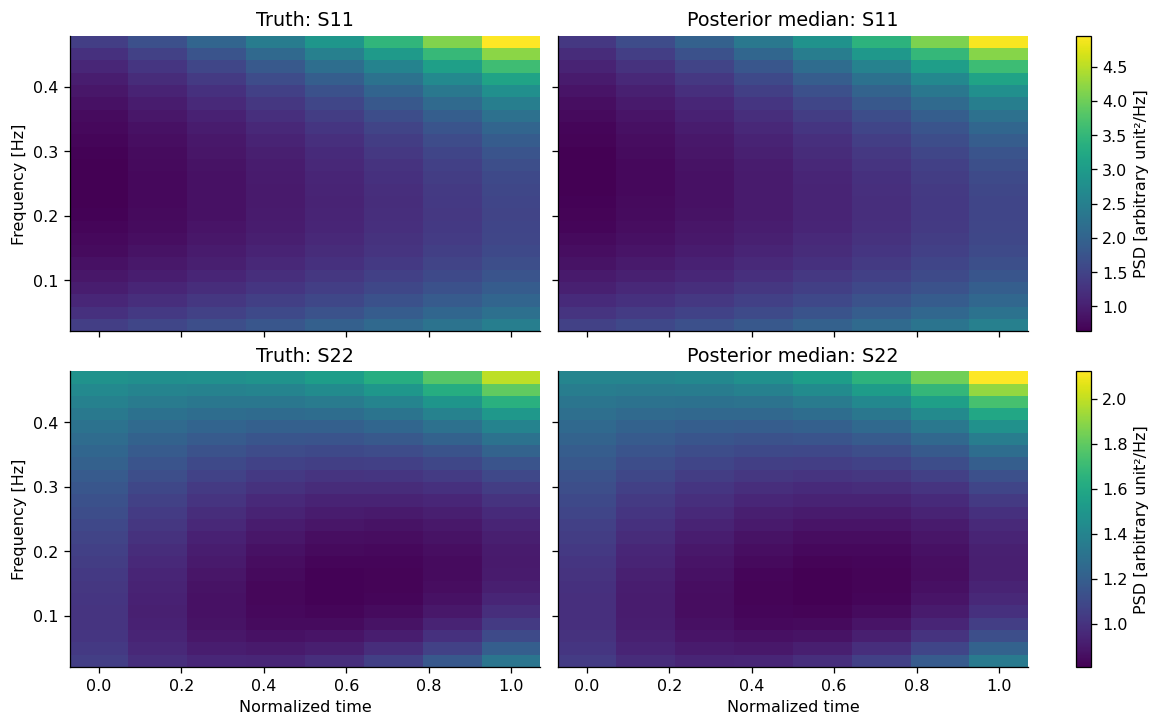

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharex=True, sharey=True, layout="constrained")
for channel in range(2):
    panels = [truth[..., channel, channel].real, median[..., channel, channel].real]
    low, high = min(a.min() for a in panels), max(a.max() for a in panels)
    for column, (label, values) in enumerate(zip(["Truth", "Posterior median"], panels)):
        ax = axes[channel, column]
        mesh = ax.pcolormesh(time, frequency, values.T, shading="nearest", cmap="viridis", vmin=low, vmax=high)
        ax.set_title(f"{label}: S{channel + 1}{channel + 1}")
        if column == 0:
            ax.set_ylabel("Frequency [Hz]")
    fig.colorbar(mesh, ax=axes[channel, :], label="PSD [arbitrary unit²/Hz]")
for ax in axes[-1]:
    ax.set_xlabel("Normalized time")
plt.show()

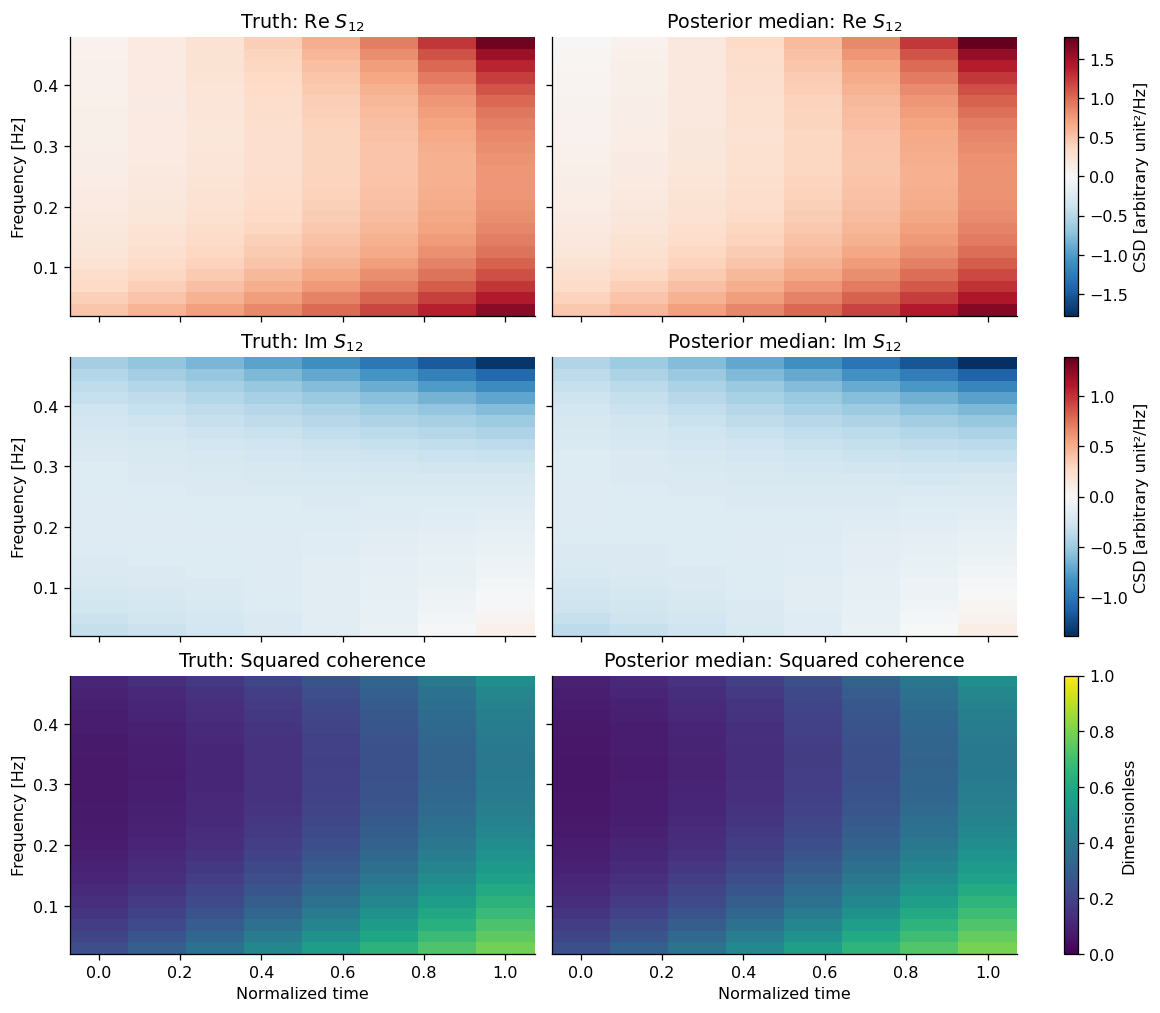

In [7]:
fields = [
    (r"Re $S_{12}$", truth[..., 0, 1].real, real_q[1, ..., 0, 1], "CSD [arbitrary unit²/Hz]"),
    (r"Im $S_{12}$", truth[..., 0, 1].imag, imag_q[1, ..., 0, 1], "CSD [arbitrary unit²/Hz]"),
    ("Squared coherence", truth_coherence, coherence_q[1], "Dimensionless"),
]
fig, axes = plt.subplots(3, 2, figsize=(10, 8.7), sharex=True, sharey=True, layout="constrained")
for row, (name, actual, estimated, units) in enumerate(fields):
    bound = max(np.max(abs(actual)), np.max(abs(estimated)))
    limits = dict(vmin=0, vmax=1, cmap="viridis") if row == 2 else dict(vmin=-bound, vmax=bound, cmap="RdBu_r")
    for column, (label, values) in enumerate(zip(["Truth", "Posterior median"], [actual, estimated])):
        ax = axes[row, column]
        mesh = ax.pcolormesh(time, frequency, values.T, shading="nearest", **limits)
        ax.set_title(f"{label}: {name}")
        if column == 0:
            ax.set_ylabel("Frequency [Hz]")
    fig.colorbar(mesh, ax=axes[row, :], label=units)
for ax in axes[-1]:
    ax.set_xlabel("Normalized time")
plt.show()

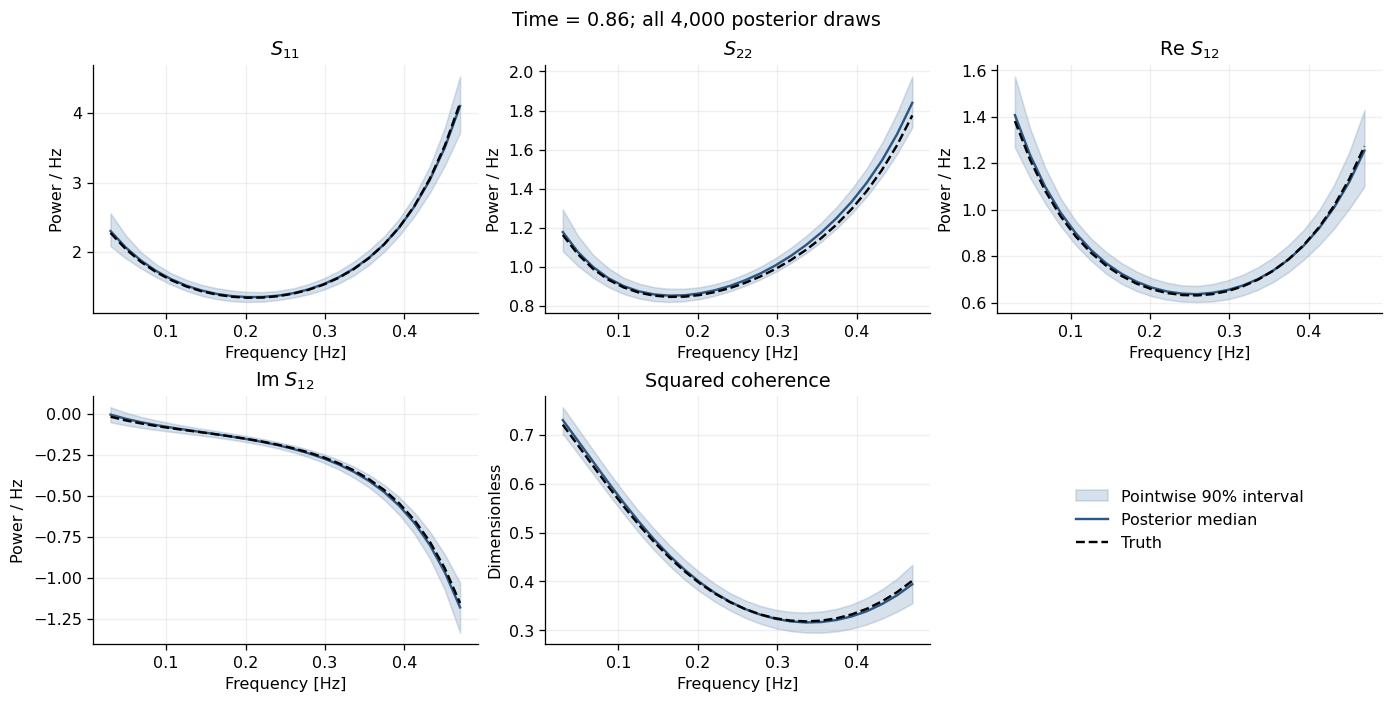

,This realization only
PSD log-ratio RMSE,0.020254
Normalized complex-CSD RMSE,0.022527
Squared-coherence RMSE,0.007822


In [8]:
# Preselected late-time slice; bands are marginal, equal-tailed 90% intervals.
slice_index = 6
slice_fields = [
    (r"$S_{11}$", truth[..., 0, 0].real, real_q[..., 0, 0]),
    (r"$S_{22}$", truth[..., 1, 1].real, real_q[..., 1, 1]),
    (r"Re $S_{12}$", truth[..., 0, 1].real, real_q[..., 0, 1]),
    (r"Im $S_{12}$", truth[..., 0, 1].imag, imag_q[..., 0, 1]),
    ("Squared coherence", truth_coherence, coherence_q),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for ax, (name, actual, quantiles) in zip(axes.flat, slice_fields):
    lower, center, upper = quantiles[:, slice_index]
    ax.fill_between(frequency, lower, upper, color="#4C78A8", alpha=0.22, label="Pointwise 90% interval")
    ax.plot(frequency, center, color="#2A5783", label="Posterior median")
    ax.plot(frequency, actual[slice_index], "--", color="black", label="Truth")
    ax.set(title=name, xlabel="Frequency [Hz]", ylabel="Dimensionless" if name == "Squared coherence" else "Power / Hz")
    ax.grid(alpha=0.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[-1, -1].axis("off")
axes[-1, -1].legend(handles, labels, loc="center", frameon=False)
fig.suptitle(f"Time = {time[slice_index]:.2f}; all 4,000 posterior draws")
plt.show()

true_psd = np.diagonal(truth, axis1=-2, axis2=-1).real
median_psd = np.diagonal(median, axis1=-2, axis2=-1).real
csd_residual = (median[..., 0, 1] - truth[..., 0, 1]) / np.sqrt(true_psd.prod(axis=-1))
recovery = {
    "PSD log-ratio RMSE": float(np.sqrt(np.mean(np.log(median_psd / true_psd)**2))),
    "Normalized complex-CSD RMSE": float(np.sqrt(np.mean(abs(csd_residual)**2))),
    "Squared-coherence RMSE": float(np.sqrt(np.mean((coherence_q[1] - truth_coherence)**2))),
}
display(pd.Series(recovery, name="This realization only").to_frame())

## What this example establishes, and the next test

The printed diagnostics and plots check a genuinely time-varying, full complex spectral matrix under an exact coefficient likelihood. The truth is deliberately smooth and representable by the chosen small basis, with many independent observations per cell. This is an inference tutorial, not evidence that these knots, priors, or data counts are suitable for every problem. Repeated simulations with different spectra, phases, coherence strengths, counts and seeds are needed to assess bias and interval coverage.

For an actual uniformly sampled two-channel record, the local Fourier frontend is:

```python
from log_psplines import TimeSeries, local_wishart_grid

series = TimeSeries(values, t=sample_times)  # values.shape == (N, 2)
observations = local_wishart_grid(series, segment_length=1024, window=None)
```

This recipe needs your own `values` and `sample_times`; it is not part of the executed coefficient simulation. The length must contain complete segments. The frontend removes **one full-record mean per channel**, then forms nonoverlapping local FFTs, excludes DC and even-length Nyquist, and uses physical one-sided PSD normalization. It performs no block-by-block detrending or channel standardization. A native cell has count one, unlike the 32 independent replicates here. Choose a basis on the resulting time/frequency domains before fitting.

For finite colored or time-varying records, the independent proper Gaussian local-coefficient likelihood is a Whittle approximation; tapering and local stationarity need their own checks. Real WDM coefficients cannot be made suitable by casting them to complex: a same-cell real covariance does not identify the full complex spectral matrix. The stationary restriction is obtained with `LogPSpline(frequency=basis_frequency, time=None)`; a stationary truth fitted with a flexible time basis is a separate diagnostic. Both checks should precede a long LISA analysis.